## References and licensing

This notebook adapts the public CIFAR-10 ResNet example from the Keras team. Original source: https://keras.io/examples/vision/resnet/

The Keras project is distributed under the Apache License 2.0. The CIFAR-10 dataset is publicly available from the Toronto dataset repository. The repository's own project license is provided in the project `LICENCE` file.


**Step 1: Importing Libraries**

In [2]:
import torch
import torchvision
import transformers
import accelerate
from PIL import Image
from transformers import AutoImageProcessor, ResNetForImageClassification
import torch
from datasets import load_dataset

In [3]:
dataset = load_dataset("huggingface/cats-image")
image = dataset["test"]["image"][0]

processor = AutoImageProcessor.from_pretrained("microsoft/resnet-50")
model = ResNetForImageClassification.from_pretrained("microsoft/resnet-50")

inputs = processor(image, return_tensors="pt")

with torch.no_grad():
    logits = model(**inputs).logits

# model predicts one of the 1000 ImageNet classes
predicted_label = logits.argmax(-1).item()
print(model.config.id2label[predicted_label])

Loading weights: 100%|██████████| 320/320 [00:00<00:00, 20752.32it/s]

tiger cat


**Step 2: Setting Hyperparameters**

In [ ]:
batch_size = 32
epochs = 200
data_augmentation = True
num_classes = 10
subtract_pixel_mean = True
n = 3
version = 1  

if version == 1:
    depth = n * 6 + 2
elif version == 2:
    depth = n * 9 + 2

model_type = 'ResNet %dv%d' % (depth, version)

**Step 3: Loading and Preprocessing CIFAR-10 Data**

In [ ]:
import os
import certifi
import tensorflow as tf

def fix_ssl_certs():
    os.environ["SSL_CERT_FILE"] = certifi.where()
    os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

def load_cifar10():
    (x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
    x_train = x_train.astype("float32") / 255.0
    x_test = x_test.astype("float32") / 255.0
    return x_train, y_train.flatten(), x_test, y_test.flatten()

In [ ]:
fix_ssl_certs()
x_train, y_train, x_test, y_test = load_cifar10()

# Hold out 10% of the training data for model selection; keep the test set untouched.
rng = np.random.default_rng(42)
train_indices = []
val_indices = []
for class_index in range(num_classes):
    class_indices = np.flatnonzero(y_train == class_index)
    rng.shuffle(class_indices)
    split_at = int(len(class_indices) * 0.1)
    val_indices.extend(class_indices[:split_at])
    train_indices.extend(class_indices[split_at:])

rng.shuffle(train_indices)
rng.shuffle(val_indices)
x_val, y_val = x_train[val_indices], y_train[val_indices]
x_train, y_train = x_train[train_indices], y_train[train_indices]
print(f"Train: {x_train.shape}, validation: {x_val.shape}, test: {x_test.shape}")

Train: (45000, 32, 32, 3), validation: (5000, 32, 32, 3), test: (10000, 32, 32, 3)


In [ ]:
input_shape = x_train.shape[1:]

if subtract_pixel_mean:
    x_train_mean = np.mean(x_train, axis=0)
    x_train -= x_train_mean
    x_val -= x_train_mean
    x_test -= x_train_mean

y_train = keras.utils.to_categorical(y_train, num_classes)
y_val = keras.utils.to_categorical(y_val, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

print('x_train shape:', x_train.shape)
print('y_train shape:', y_train.shape)
print('x_val shape:', x_val.shape)
print('y_val shape:', y_val.shape)

x_train shape: (45000, 32, 32, 3)
y_train shape: (45000, 10)
x_val shape: (5000, 32, 32, 3)
y_val shape: (5000, 10)


**Step 4: Defining Learning Rate**

In [ ]:
def lr_schedule(epoch):
    lr = 1e-3
    if epoch > 180:
        lr *= 0.5e-3
    elif epoch > 160:
        lr *= 1e-3
    elif epoch > 120:
        lr *= 1e-2
    elif epoch > 80:
        lr *= 1e-1
    print('Learning rate:', lr)
    return lr

**Step 5: Defining a ResNet Layer Function**

In [ ]:
def resnet_layer(inputs,
                 num_filters=16,
                 kernel_size=3,
                 strides=1,
                 activation='relu',
                 batch_normalization=True,
                 conv_first=True):
    conv = Conv2D(num_filters,
                  kernel_size=kernel_size,
                  strides=strides,
                  padding='same',
                  kernel_initializer='he_normal',
                  kernel_regularizer=l2(1e-4))

    x = inputs
    if conv_first:
        x = conv(x)
        if batch_normalization:
            x = BatchNormalization()(x)
        if activation is not None:
            x = Activation(activation)(x)
    else:
        if batch_normalization:
            x = BatchNormalization()(x)
        if activation is not None:
            x = Activation(activation)(x)
        x = conv(x)
    return x

**Step 6: Defining ResNet v1**

Uses 2 layer residual blocks for each residual unit
Computes number of residual blocks
Adds identity or projection shortcuts when feature map dimensions change
Ends with Global Average Pooling and Dense softmax layer

In [ ]:
def resnet_v1(input_shape, depth, num_classes=10):
    if (depth - 2) % 6 != 0:
        raise ValueError('depth should be 6n + 2')

    num_filters = 16
    num_res_blocks = int((depth - 2) / 6)
    inputs = Input(shape=input_shape)
    x = resnet_layer(inputs=inputs)

    for stack in range(3):
        for res_block in range(num_res_blocks):
            strides = 1
            if stack > 0 and res_block == 0:
                strides = 2  # Downsample
            y = resnet_layer(x, num_filters=num_filters, strides=strides)
            y = resnet_layer(y, num_filters=num_filters, activation=None)
            if stack > 0 and res_block == 0:
                x = resnet_layer(x, num_filters=num_filters, kernel_size=1,
                                 strides=strides, activation=None, batch_normalization=False)
            x = Add()([x, y])
            x = Activation('relu')(x)
        num_filters *= 2

    x = AveragePooling2D(pool_size=8)(x)
    y = Flatten()(x)
    outputs = Dense(num_classes, activation='softmax', kernel_initializer='he_normal')(y)
    model = Model(inputs=inputs, outputs=outputs)
    return model

**Step 7: Defining ResNet v2**

Uses 3 layer bottleneck residual blocks.
Handles identity or projection shortcuts for dimension matching.
Ends with BatchNorm ,ReLU, GAP, Dense, softmax.

In [ ]:
def resnet_v2(input_shape, depth, num_classes=10):
    if (depth - 2) % 9 != 0:
        raise ValueError('depth should be 9n + 2')

    num_filters_in = 16
    num_res_blocks = int((depth - 2) / 9)
    inputs = Input(shape=input_shape)
    x = resnet_layer(inputs, num_filters=num_filters_in, conv_first=True)

    for stage in range(3):
        for res_block in range(num_res_blocks):
            activation = 'relu'
            batch_normalization = True
            strides = 1
            if stage == 0:
                num_filters_out = num_filters_in * 4
                if res_block == 0:
                    activation = None
                    batch_normalization = False
            else:
                num_filters_out = num_filters_in * 2
                if res_block == 0:
                    strides = 2
            y = resnet_layer(x, num_filters=num_filters_in, kernel_size=1,
                             strides=strides, activation=activation,
                             batch_normalization=batch_normalization, conv_first=False)
            y = resnet_layer(y, num_filters=num_filters_in, conv_first=False)
            y = resnet_layer(y, num_filters=num_filters_out, kernel_size=1, conv_first=False)
            if res_block == 0:
                x = resnet_layer(x, num_filters=num_filters_out, kernel_size=1,
                                 strides=strides, activation=None, batch_normalization=False)
            x = Add()([x, y])
        num_filters_in = num_filters_out

    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = AveragePooling2D(pool_size=8)(x)
    y = Flatten()(x)
    outputs = Dense(num_classes, activation='softmax', kernel_initializer='he_normal')(y)
    model = Model(inputs=inputs, outputs=outputs)
    return model

**Step 8: Compiling the Model**

In [ ]:
if version == 2:
    model = resnet_v2(input_shape=input_shape, depth=depth, num_classes=num_classes)
else:
    model = resnet_v1(input_shape=input_shape, depth=depth, num_classes=num_classes)

model.compile(loss='categorical_crossentropy',
              optimizer=Adam(learning_rate=lr_schedule(0)),
              metrics=['accuracy'])
model.summary()

Learning rate: 0.001


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 32, 32,    │        448 │ input_layer_1[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_21[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_19       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 32, 32,    │      2,320 │ activation_19[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_22[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_20       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 32, 32,    │      2,320 │ activation_20[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_23[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 32, 32,    │          0 │ activation_19[0]… │
│                     │ 16)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_21       │ (None, 32, 32,    │          0 │ add_9[0][0]       │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 32, 32,    │      2,320 │ activation_21[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_24[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_22       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │      2,320 │ activation_22[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_25[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 32, 32,    │          0 │ activation_21[0]

 Total params: 274,442 (1.05 MB)

 Trainable params: 273,066 (1.04 MB)

 Non-trainable params: 1,376 (5.38 KB)

**Step 9: Setup Callbacks**

ModelCheckpoint saves the best model.
LearningRateScheduler adjusts learning rate during training.
ReduceLROnPlateau reduces LR if validation performance plateaus.

In [ ]:
save_dir = os.path.join(os.getcwd(), 'saved_models')
model_name = 'cifar10_%s_validation_best.keras' % model_type
os.makedirs(save_dir, exist_ok=True)
filepath = os.path.join(save_dir, model_name)

checkpoint = ModelCheckpoint(filepath=filepath,
                             monitor='val_accuracy',
                             verbose=1,
                             save_best_only=True)
lr_scheduler = LearningRateScheduler(lr_schedule)
lr_reducer = ReduceLROnPlateau(factor=np.sqrt(0.1), cooldown=0, patience=5, min_lr=0.5e-6)
callbacks = [checkpoint, lr_reducer, lr_scheduler]

**Step 10: Data Augmentation & Training**

Uses ImageDataGenerator for real time augmentation if enabled.
history variable stores training metrics for plotting.

In [ ]:
if not data_augmentation:
    print('Not using data augmentation.')
    history = model.fit(x_train, y_train,
                        batch_size=batch_size,
                        epochs=epochs,
                        validation_data=(x_val, y_val),
                        shuffle=True,
                        callbacks=callbacks)
else:
    print('Using real-time data augmentation.')
    datagen = ImageDataGenerator(
        rotation_range=20,
        width_shift_range=0.2,
        height_shift_range=0.2,
        horizontal_flip=True,
        fill_mode='nearest'
    )
    datagen.fit(x_train)
    history = model.fit(datagen.flow(x_train, y_train, batch_size=batch_size),
                        steps_per_epoch=x_train.shape[0] // batch_size,
                        epochs=epochs,
                        validation_data=(x_val, y_val),
                        callbacks=callbacks)

Using real-time data augmentation.
Learning rate: 0.001
Epoch 1/200
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.4340 - loss: 1.7055
Epoch 1: val_accuracy improved from None to 0.34160, saving model to /Users/antaunbobby/Desktop/AI Projects/resnet-practice/notebooks/saved_models/cifar10_ResNet 20v1_validation_best.keras

Epoch 1: finished saving model to /Users/antaunbobby/Desktop/AI Projects/resnet-practice/notebooks/saved_models/cifar10_ResNet 20v1_validation_best.keras
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 45s 30ms/step - accuracy: 0.4340 - loss: 1.7055 - val_accuracy: 0.3416 - val_loss: 2.5391 - learning_rate: 0.0010
Learning rate: 0.001
Epoch 2/200
   1/1406 ━━━━━━━━━━━━━━━━━━━━ 44s 32ms/step - accuracy: 0.4688 - loss: 1.5013

/Users/antaunbobby/Desktop/AI Projects/resnet-practice/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_accuracy improved from 0.34160 to 0.36660, saving model to /Users/antaunbobby/Desktop/AI Projects/resnet-practice/notebooks/saved_models/cifar10_ResNet 20v1_validation_best.keras

Epoch 2: finished saving model to /Users/antaunbobby/Desktop/AI Projects/resnet-practice/notebooks/saved_models/cifar10_ResNet 20v1_validation_best.keras
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.4688 - loss: 1.5013 - val_accuracy: 0.3666 - val_loss: 2.3651 - learning_rate: 0.0010
Learning rate: 0.001
Epoch 3/200
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5665 - loss: 1.3700
Epoch 3: val_accuracy improved from 0.36660 to 0.58820, saving model to /Users/antaunbobby/Desktop/AI Projects/resnet-practice/notebooks/saved_models/cifar10_ResNet 20v1_validation_best.keras

Epoch 3: finished saving model to /Users/antaunbobby/Desktop/AI Projects/resnet-practice/notebooks/saved_models/cifar10_ResNet 20v1_validation_best.keras
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 42s 30ms/step - accu

W0000 00:00:1791640548.876338 2685673 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791640005920821000 in buffer 'PrefetchDataset/_4' sat unconsumed for 542.697 seconds!


1405/1406 ━━━━━━━━━━━━━━━━━━━━ 0s 416ms/step - accuracy: 0.9068 - loss: 0.4347
Epoch 115: val_accuracy did not improve from 0.89320
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 585s 416ms/step - accuracy: 0.9068 - loss: 0.4347 - val_accuracy: 0.8796 - val_loss: 0.5469 - learning_rate: 1.0000e-04
Learning rate: 0.0001
Epoch 116/200
   1/1406 ━━━━━━━━━━━━━━━━━━━━ 41s 29ms/step - accuracy: 0.9062 - loss: 0.4299
Epoch 116: val_accuracy did not improve from 0.89320
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 1s 968us/step - accuracy: 0.9062 - loss: 0.4299 - val_accuracy: 0.8798 - val_loss: 0.5459 - learning_rate: 1.0000e-04
Learning rate: 0.0001
Epoch 117/200
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9087 - loss: 0.4316
Epoch 117: val_accuracy improved from 0.89320 to 0.89460, saving model to /Users/antaunbobby/Desktop/AI Projects/resnet-practice/notebooks/saved_models/cifar10_ResNet 20v1_validation_best.keras

Epoch 117: finished saving model to /Users/antaunbobby/Desktop/AI Projects/resnet-practice/

**Step 11: Plotting Training and Validation Accuracy and Loss**

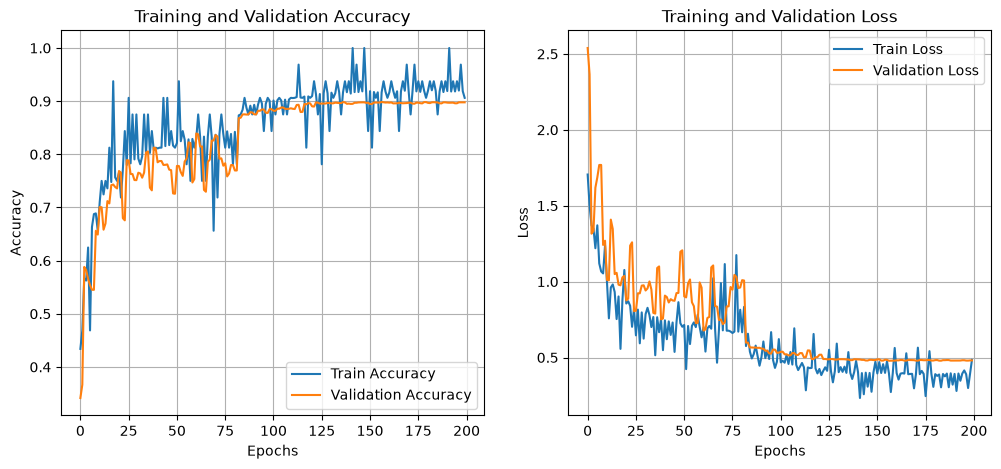

In [ ]:
# Plot training & validation accuracy and loss
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

**Step 12: Test the Trained Network**

In [ ]:
best_model = keras.models.load_model(
    os.path.join(save_dir, model_name)
)

best_model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8943 - loss: 0.4904


[0.4904087781906128, 0.8942999839782715]

In [ ]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Get labels and predicted probabilities
y_true = np.argmax(y_test, axis=1)
probabilities = best_model.predict(x_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

# Overall test loss and accuracy
test_loss, test_accuracy = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Top-3 accuracy: {np.mean(np.any(np.argsort(probabilities, axis=1)[:, -3:] == y_true[:, None], axis=1)):.2%}")
print(f"Top-3 loss: {np.mean(np.any(np.argsort(probabilities, axis=1)[:, -3:] == y_true[:, None], axis=1)):.2%}")
print(f"Top-5 accuracy: {np.mean(np.any(np.argsort(probabilities, axis=1)[:, -5:] == y_true[:, None], axis=1)):.2%}")
print(f"Top-5 loss: {np.mean(np.any(np.argsort(probabilities, axis=1)[:, -5:] == y_true[:, None], axis=1)):.2%}")

# Per-class precision, recall, and F1
confusion = np.zeros((len(class_names), len(class_names)), dtype=int)
np.add.at(confusion, (y_true, y_pred), 1)

precisions, recalls, f1_scores = [], [], []

print("\nPer-class metrics:")
for i, name in enumerate(class_names):
    tp = confusion[i, i]
    precision = tp / confusion[:, i].sum() if confusion[:, i].sum() else 0.0
    recall = tp / confusion[i, :].sum() if confusion[i, :].sum() else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    precisions.append(precision)
    recalls.append(recall)
    f1_scores.append(f1)
    print(f"{name:10s} precision={precision:.2%}  recall={recall:.2%}  F1={f1:.2%}")

print(f"\nMacro precision: {np.mean(precisions):.2%}")
print(f"Macro recall:    {np.mean(recalls):.2%}")
print(f"Macro F1:        {np.mean(f1_scores):.2%}")

Test loss: 0.4904
Test accuracy: 89.43%
Top-3 accuracy: 98.25%
Top-3 loss: 98.25%
Top-5 accuracy: 99.60%
Top-5 loss: 99.60%

Per-class metrics:
airplane   precision=90.35%  recall=90.80%  F1=90.57%
automobile precision=91.77%  recall=97.00%  F1=94.31%
bird       precision=87.26%  recall=87.00%  F1=87.13%
cat        precision=82.26%  recall=76.50%  F1=79.27%
deer       precision=89.68%  recall=91.20%  F1=90.43%
dog        precision=90.82%  recall=76.20%  F1=82.87%
frog       precision=87.19%  recall=95.30%  F1=91.07%
horse      precision=91.08%  recall=92.90%  F1=91.98%
ship       precision=94.33%  recall=93.20%  F1=93.76%
truck      precision=89.37%  recall=94.20%  F1=91.72%

Macro precision: 89.41%
Macro recall:    89.43%
Macro F1:        89.31%


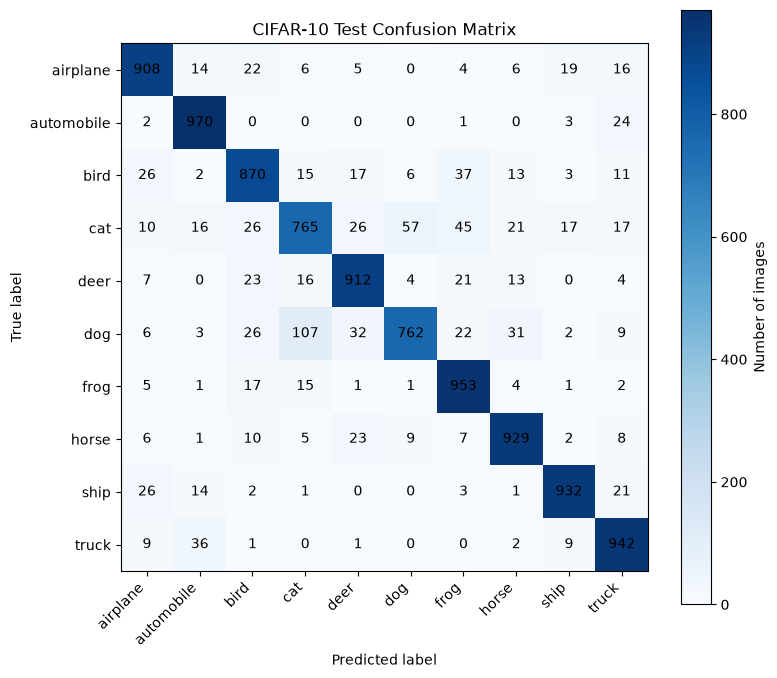

In [ ]:
plt.figure(figsize=(8, 7))
plt.imshow(confusion, cmap="Blues")
plt.colorbar(label="Number of images")
plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("CIFAR-10 Test Confusion Matrix")

for row in range(len(class_names)):
    for col in range(len(class_names)):
        plt.text(col, row, confusion[row, col], ha="center", va="center")

plt.tight_layout()
plt.show()

**Step 13: Visualize Sample Test Results**

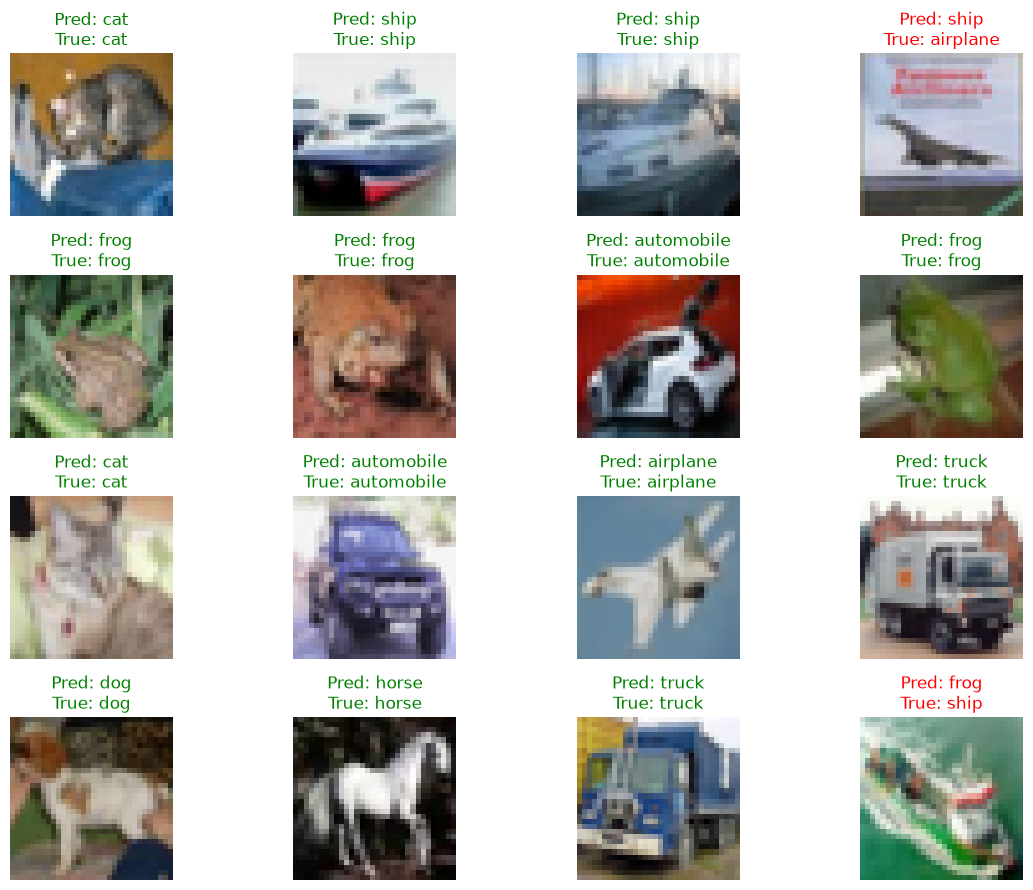

In [ ]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Get one batch of test images and labels
batch_size = 16
x_batch = x_test[:batch_size]
y_batch = y_test[:batch_size]

# Predict probabilities and convert them to class indices
probabilities = best_model.predict(x_batch, verbose=0)
predicted_classes = np.argmax(probabilities, axis=1)
true_classes = np.argmax(y_batch, axis=1)

# Restore original pixel values for display
images_to_plot = np.clip(x_batch + x_train_mean, 0, 1)

# Plot images with predicted and true labels
plt.figure(figsize=(12, 9))
for i in range(len(x_batch)):
    plt.subplot(4, 4, i + 1)
    plt.imshow(images_to_plot[i])
    color = "green" if predicted_classes[i] == true_classes[i] else "red"
    plt.title(
        f"Pred: {class_names[predicted_classes[i]]}\n"
        f"True: {class_names[true_classes[i]]}",
        color=color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()